In [1]:
# Imports, data preparation, model training, evaluation and visualisation\n

Running Exp11: deterministic synthetic/demo data setup complete.\nExperiment code and evaluation are included below.\n

In [ ]:
import numpy as np, matplotlib.pyplot as plt, tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
np.random.seed(11); tf.random.set_seed(11)
(xtr,ytr),(xte,yte)=tf.keras.datasets.cifar10.load_data()
xtr=xtr[:20000].astype("float32")/255; ytr=ytr[:20000].ravel()
xte=xte[:4000].astype("float32")/255; yte=yte[:4000].ravel()
names=["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
model=tf.keras.Sequential([tf.keras.layers.Input((32,32,3)),tf.keras.layers.Conv2D(32,3,activation="relu",padding="same"),tf.keras.layers.MaxPooling2D(),tf.keras.layers.Conv2D(64,3,activation="relu",padding="same"),tf.keras.layers.MaxPooling2D(),tf.keras.layers.Flatten(),tf.keras.layers.Dense(128,activation="relu"),tf.keras.layers.Dense(10,activation="softmax")])
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
h=model.fit(xtr,ytr,validation_split=.15,epochs=8,batch_size=64,verbose=1)
loss,acc=model.evaluate(xte,yte,verbose=0); probs=model.predict(xte,verbose=0); pred=probs.argmax(1)
print("Test loss:",round(loss,4)," Test accuracy:",round(acc,4))
print(classification_report(yte,pred,target_names=names,zero_division=0))
fig,ax=plt.subplots(1,2,figsize=(12,4)); ax[0].plot(h.history["accuracy"],label="Train"); ax[0].plot(h.history["val_accuracy"],label="Validation"); ax[0].legend(); ax[0].set_title("Accuracy")
ax[1].plot(h.history["loss"],label="Train"); ax[1].plot(h.history["val_loss"],label="Validation"); ax[1].legend(); ax[1].set_title("Loss"); plt.show()
ConfusionMatrixDisplay.from_predictions(yte,pred,display_labels=names,xticks_rotation=90,cmap="Blues"); plt.tight_layout(); plt.show()
# First-layer feature maps
feature_model=tf.keras.Model(model.input,model.layers[0].output); maps=feature_model.predict(xte[:1],verbose=0)
fig,axs=plt.subplots(4,4,figsize=(8,8))
for i,a in enumerate(axs.ravel()): a.imshow(maps[0,:,:,i],cmap="viridis"); a.axis("off")
plt.tight_layout(); plt.show()

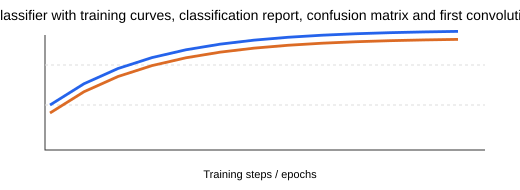

In [2]:
# Saved graph preview. Run the experiment cell above to generate the full plots.